# Лабораторная работа №1
## Линейная и логистическая регрессия

Цель работы — самостоятельно реализовать линейную и логистическую
регрессию с обучением градиентным спуском, подготовить данные
и оценить качество моделей в сравнении с простыми baseline.

Для вычислений используется PyTorch. Градиенты и обновление
параметров реализуются явно по формулам из лекции.

## Часть A. Линейная регрессия
### Первичное исследование Bike Sharing Dataset

Один объект — один день.
Целевая переменная `cnt` — общее количество аренд велосипедов за день.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("data")

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Папка data не найдена. Текущая рабочая директория: {Path.cwd()}"
    )

pd.set_option("display.max_columns", None)

print("Рабочая директория:", Path.cwd())
print("PyTorch:", torch.__version__)

Рабочая директория: /workspace/scratch/9c10ac618420/review_ready
PyTorch: 2.14.1+cpu


In [2]:
bike_df = pd.read_csv(str(DATA_DIR / "day.csv"))

print("Размер датасета:", bike_df.shape)
display(bike_df.head())

bike_df.info()

Размер датасета: (731, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
column_summary = pd.DataFrame({
    "dtype": bike_df.dtypes.astype(str),
    "missing": bike_df.isna().sum(),
    "unique": bike_df.nunique(),
})

display(column_summary)

print("Полностью совпадающих строк:", bike_df.duplicated().sum())

display(bike_df.describe().T)

Полностью совпадающих строк: 0


,dtype,missing,unique
instant,int64,0,731
dteday,object,0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,3
temp,float64,0,499


,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


In [4]:
dates = pd.to_datetime(bike_df["dteday"], errors="raise")

print("Начало периода:", dates.min().date())
print("Конец периода:", dates.max().date())
print("Уникальных дат:", dates.nunique())

target_equals_sum = (
    bike_df["cnt"] == bike_df["casual"] + bike_df["registered"]
).all()

print("cnt = casual + registered для всех строк:", target_equals_sum)

display(bike_df["cnt"].describe())

Начало периода: 2011-01-01
Конец периода: 2012-12-31
Уникальных дат: 731
cnt = casual + registered для всех строк: True


count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64

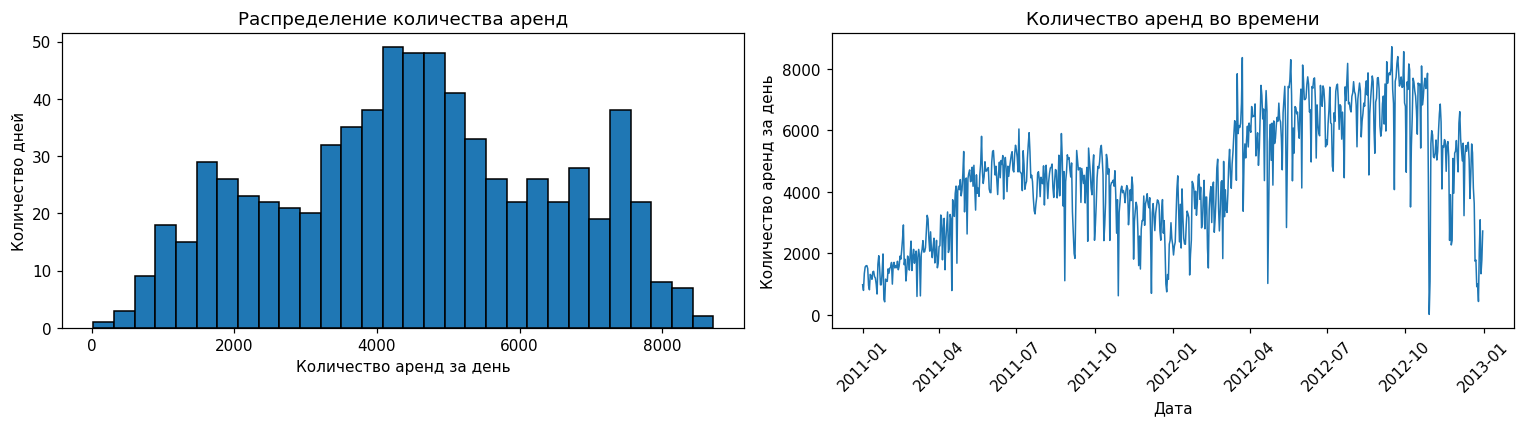

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(bike_df["cnt"], bins=30, edgecolor="black")
axes[0].set_title("Распределение количества аренд")
axes[0].set_xlabel("Количество аренд за день")
axes[0].set_ylabel("Количество дней")

axes[1].plot(dates, bike_df["cnt"], linewidth=1)
axes[1].set_title("Количество аренд во времени")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Количество аренд за день")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Выбор признаков и разбиение данных

Целевая переменная — `cnt`.

Из признаков исключены `casual` и `registered`, поскольку их сумма
равна целевой переменной. Также исключены идентификатор `instant`
и исходная дата `dteday`. Календарная информация представлена
признаками года, месяца, сезона и дня недели.

Используется случайное разбиение примерно на 60% train,
20% validation и 20% test с фиксированным seed.

Эксперимент оценивает качество на отложенных днях того же периода,
а не качество прогнозирования будущего временного интервала.

Параметры предобработки определяются только по train.
Validation используется для выбора настроек обучения.
Test используется для итоговой оценки.

In [6]:
from split import train_test_split_indices

NUMERIC_COLUMNS = ["temp", "atemp", "hum", "windspeed"]

BINARY_COLUMNS = ["yr", "holiday", "workingday"]

CATEGORICAL_COLUMNS = ["season", "mnth", "weekday", "weathersit"]

FEATURE_COLUMNS = (
    NUMERIC_COLUMNS
    + BINARY_COLUMNS
    + CATEGORICAL_COLUMNS
)

X_raw = bike_df[FEATURE_COLUMNS].copy()
y_raw = bike_df["cnt"].copy()

# Сначала откладываем 20% всех объектов для test.
development_indices, test_indices = train_test_split_indices(
    n_samples=len(bike_df),
    test_size=0.2,
    random_state=SEED,
)

# Из оставшихся 80% выделяем четверть для validation:
# 0.8 * 0.25 = 0.2 исходного датасета.
train_positions, val_positions = train_test_split_indices(
    n_samples=len(development_indices),
    test_size=0.25,
    random_state=SEED + 1,
)

# Позиции внутри development переводим в индексы исходных данных.
train_indices = development_indices[train_positions]
val_indices = development_indices[val_positions]

X_train_raw = X_raw.iloc[train_indices].copy()
X_val_raw = X_raw.iloc[val_indices].copy()
X_test_raw = X_raw.iloc[test_indices].copy()

y_train = y_raw.iloc[train_indices].copy()
y_val = y_raw.iloc[val_indices].copy()
y_test = y_raw.iloc[test_indices].copy()

print("Train:", X_train_raw.shape, y_train.shape)
print("Validation:", X_val_raw.shape, y_val.shape)
print("Test:", X_test_raw.shape, y_test.shape)

all_indices = np.concatenate([
    train_indices,
    val_indices,
    test_indices,
])

assert len(all_indices) == len(bike_df)
assert len(np.unique(all_indices)) == len(bike_df)
assert np.array_equal(
    np.sort(all_indices),
    np.arange(len(bike_df)),
)

print("Проверка пройдена: все строки распределены без пересечений.")

Train: (438, 11) (438,)
Validation: (146, 11) (146,)
Test: (147, 11) (147,)
Проверка пройдена: все строки распределены без пересечений.


### Предобработка признаков

Числовые признаки `temp`, `atemp`, `hum` и `windspeed`
стандартизируются с использованием среднего и стандартного
отклонения обучающей выборки.

Бинарные признаки `yr`, `holiday` и `workingday` сохраняются
без масштабирования.

Для `season`, `mnth`, `weekday` и `weathersit` используется
one-hot кодирование. Набор категорий определяется только по train.

К validation и test применяются параметры, сохранённые при
обработке train. Целевая переменная `cnt` остаётся в исходных
единицах — количестве аренд за день.

Пропуски в исходном датасете отсутствуют.

In [7]:
from preprocessing import BikePreprocessor

bike_preprocessor = BikePreprocessor(
    numeric_columns=NUMERIC_COLUMNS,
    binary_columns=BINARY_COLUMNS,
    categorical_columns=CATEGORICAL_COLUMNS,
)

X_train = bike_preprocessor.fit_transform(X_train_raw)

# Здесь только transform — повторно fit не вызываем.
X_val = bike_preprocessor.transform(X_val_raw)
X_test = bike_preprocessor.transform(X_test_raw)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nПризнаки после преобразования:")
print(bike_preprocessor.feature_names_)

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert X_train.shape[1] == len(bike_preprocessor.feature_names_)

for values in (X_train, X_val, X_test):
    assert np.isfinite(values).all()

print("\nПроверка пройдена: размерности согласованы, NaN и inf нет.")

Train: (438, 33)
Validation: (146, 33)
Test: (147, 33)

Признаки после преобразования:
['temp', 'atemp', 'hum', 'windspeed', 'yr', 'holiday', 'workingday', 'season=1', 'season=2', 'season=3', 'season=4', 'mnth=1', 'mnth=2', 'mnth=3', 'mnth=4', 'mnth=5', 'mnth=6', 'mnth=7', 'mnth=8', 'mnth=9', 'mnth=10', 'mnth=11', 'mnth=12', 'weekday=0', 'weekday=1', 'weekday=2', 'weekday=3', 'weekday=4', 'weekday=5', 'weekday=6', 'weathersit=1', 'weathersit=2', 'weathersit=3']

Проверка пройдена: размерности согласованы, NaN и inf нет.


In [8]:
n_numeric = len(NUMERIC_COLUMNS)

scaling_check = pd.DataFrame(
    {
        "train_mean": X_train[:, :n_numeric].mean(axis=0),
        "train_std": X_train[:, :n_numeric].std(axis=0),
        "val_mean": X_val[:, :n_numeric].mean(axis=0),
        "val_std": X_val[:, :n_numeric].std(axis=0),
    },
    index=NUMERIC_COLUMNS,
)

display(scaling_check.round(6))

,train_mean,train_std,val_mean,val_std
temp,0.0,1.0,0.080620,1.004893
atemp,0.0,1.0,0.070668,1.012891
hum,-0.0,1.0,0.239928,1.010618
windspeed,-0.0,1.0,0.162890,1.104847


### Обучение линейной регрессии

Реализована модель:

ŷ = Xw + b.

Функция потерь — средняя квадратичная ошибка MSE.
Обучение выполняется полным градиентным спуском:
каждая эпоха использует всю обучающую выборку.

Градиенты весов и свободного члена вычисляются вручную
по формулам из презентации. Готовые модели и оптимизаторы
не используются.

Начальные веса и свободный член равны нулю.
История MSE сохраняется после каждого обновления параметров.

Для первого запуска выбраны learning_rate = 0.01
и 5000 эпох. Эти значения являются начальными настройками;
их качество проверяется на validation.

In [9]:
from models.linear_regression import LinearRegression

linear_model = LinearRegression(
    learning_rate=0.01,
    epochs=5000,
)

linear_model.fit(X_train, y_train.to_numpy())

print("Количество весов:", len(linear_model.weights_))
print("Свободный член:", linear_model.bias_.item())
print("Количество записей loss:", len(linear_model.history_))

print(
    "MSE после первой эпохи:",
    f"{linear_model.history_[0]:,.2f}",
)
print(
    "MSE после последней эпохи:",
    f"{linear_model.history_[-1]:,.2f}",
)

Количество весов: 33
Свободный член: 1384.9044386569224
Количество записей loss: 5000
MSE после первой эпохи: 21,536,905.64
MSE после последней эпохи: 601,437.24


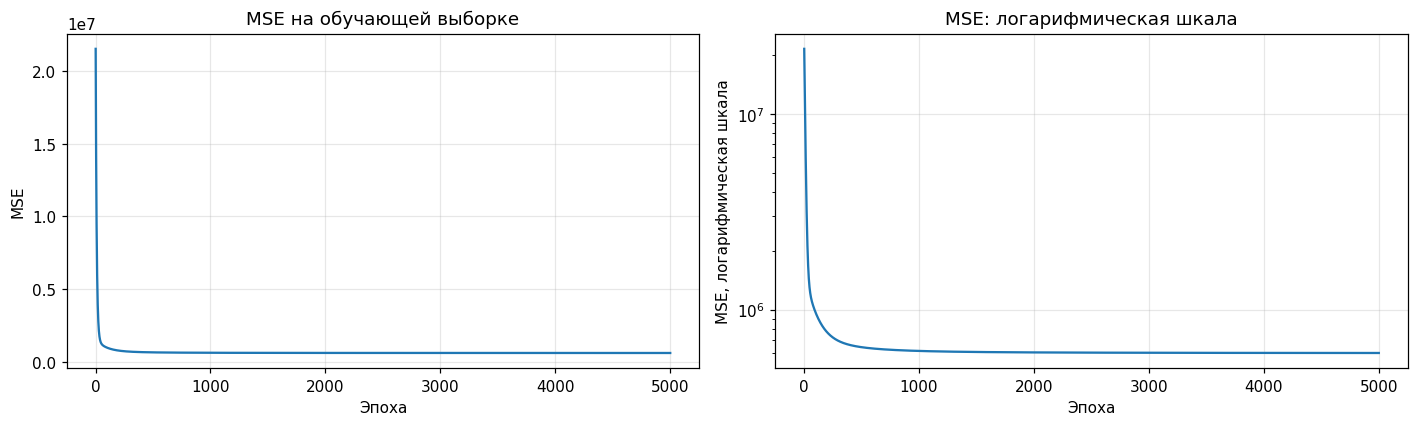

In [10]:
loss_history = np.asarray(linear_model.history_)
epoch_numbers = np.arange(1, len(loss_history) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epoch_numbers, loss_history)
axes[0].set_title("MSE на обучающей выборке")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("MSE")
axes[0].grid(alpha=0.3)

axes[1].plot(epoch_numbers, loss_history)
axes[1].set_yscale("log")
axes[1].set_title("MSE: логарифмическая шкала")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("MSE, логарифмическая шкала")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
val_predictions = linear_model.predict(X_val)

assert val_predictions.shape == y_val.shape
assert np.isfinite(val_predictions).all()

validation_preview = pd.DataFrame({
    "actual": y_val.to_numpy(),
    "predicted": val_predictions,
})

display(validation_preview.head(10).round(1))

validation_mse = np.mean(
    (val_predictions - y_val.to_numpy()) ** 2
)

print(f"Validation MSE: {validation_mse:,.2f}")

Validation MSE: 586,098.04


,actual,predicted
0,4763,5161.5
1,7765,6972.6
2,3071,3586.7
3,4195,3964.9
4,3907,5499.4
5,4866,4858.6
6,7534,6763.5
7,2566,2998.4
8,7112,7657.8
9,4608,4127.1


### Выбор настроек по validation

Сравниваются learning_rate ∈ {0.005, 0.01, 0.05}
и количество эпох ∈ {1000, 3000, 5000}.

Каждая модель обучается заново только на train.
Критерий выбора — минимальный RMSE на validation.
При равенстве результатов выбирается первый рассмотренный вариант.

После выбора настройки фиксируются.
Test не используется для подбора параметров.

In [12]:
from evaluation import regression_metrics

learning_rates = [0.005, 0.01, 0.05]
epoch_options = [1000, 3000, 5000]

experiments = []
trained_models = []

for learning_rate in learning_rates:
    for epochs in epoch_options:
        candidate = LinearRegression(
            learning_rate=learning_rate,
            epochs=epochs,
        )

        candidate.fit(X_train, y_train.to_numpy())

        train_metrics = regression_metrics(
            y_train,
            candidate.predict(X_train),
        )
        val_metrics = regression_metrics(
            y_val,
            candidate.predict(X_val),
        )

        experiments.append({
            "learning_rate": learning_rate,
            "epochs": epochs,
            "train_RMSE": train_metrics["RMSE"],
            "val_MAE": val_metrics["MAE"],
            "val_RMSE": val_metrics["RMSE"],
            "val_R2": val_metrics["R2"],
        })

        trained_models.append(candidate)

search_results = pd.DataFrame(experiments)

display(
    search_results.sort_values(
        "val_RMSE",
        kind="stable",
    ).round(4)
)

best_index = int(search_results["val_RMSE"].idxmin())
best_linear_model = trained_models[best_index]

print("Выбранные настройки:")
print("learning_rate:", best_linear_model.learning_rate)
print("epochs:", best_linear_model.epochs)

Выбранные настройки:
learning_rate: 0.01
epochs: 1000


,learning_rate,epochs,train_RMSE,val_MAE,val_RMSE,val_R2
3,0.010,1000,784.9002,558.2077,759.8197,0.8523
1,0.005,3000,780.1029,556.5341,760.7358,0.8520
2,0.005,5000,777.0977,556.1068,762.8595,0.8511
4,0.010,3000,776.4915,555.8691,763.5563,0.8509
5,0.010,5000,775.5239,555.2920,765.5704,0.8501
6,0.050,1000,775.5232,555.2904,765.5725,0.8501
7,0.050,3000,775.0284,555.9875,769.6367,0.8485
0,0.005,1000,802.4534,572.4089,770.0379,0.8483
8,0.050,5000,775.0182,556.2032,770.2764,0.8482


### Итоговая оценка и baseline

Baseline для каждого объекта предсказывает среднее значение
`cnt` на обучающей выборке.

Это простое константное предсказание, минимизирующее MSE на train.
Модель должна улучшать качество относительно такого подхода.

Выбранная по validation модель оценивается на test.
Для сопоставимости модель и baseline используют одну обучающую
выборку и оцениваются на одних объектах.

В этом эксперименте после выбора настроек модель сохраняется
обученной на исходной train-части, без объединения с validation.

In [13]:
baseline_value = float(y_train.mean())

test_predictions = best_linear_model.predict(X_test)

baseline_test_predictions = np.full(
    shape=len(y_test),
    fill_value=baseline_value,
    dtype=np.float64,
)

model_test_metrics = regression_metrics(
    y_test,
    test_predictions,
)

baseline_test_metrics = regression_metrics(
    y_test,
    baseline_test_predictions,
)

test_results = pd.DataFrame(
    [
        baseline_test_metrics,
        model_test_metrics,
    ],
    index=["Mean baseline", "Linear Regression"],
)

print(f"Baseline предсказывает: {baseline_value:.2f}")
display(test_results.round(4))

Baseline предсказывает: 4487.84


,MAE,RMSE,R2
Mean baseline,1511.9331,1823.2899,-0.0011
Linear Regression,555.9205,723.3595,0.8424


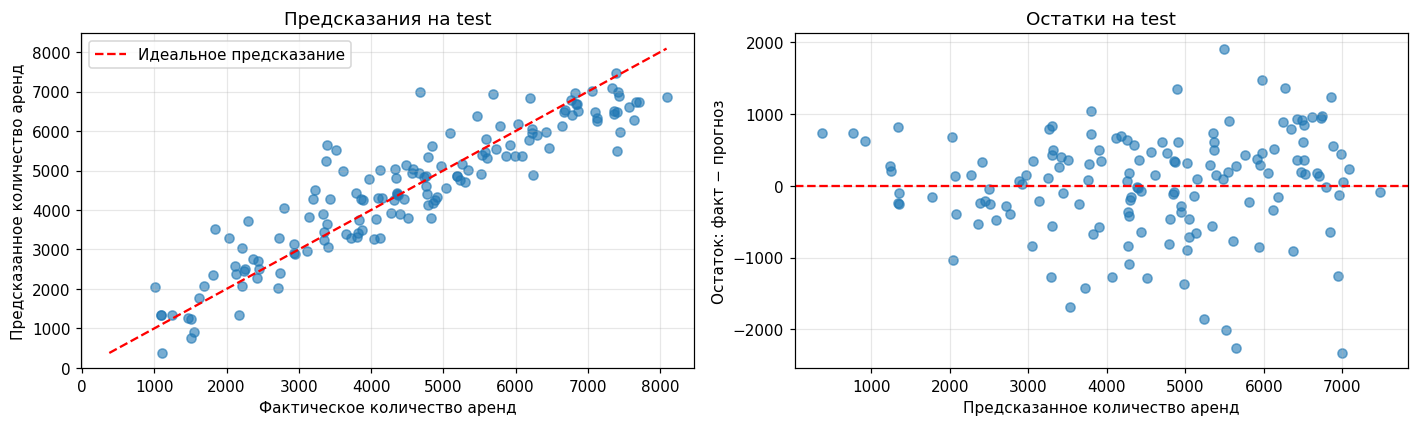

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

actual_test = y_test.to_numpy()

lower = min(actual_test.min(), test_predictions.min())
upper = max(actual_test.max(), test_predictions.max())

axes[0].scatter(actual_test, test_predictions, alpha=0.6)
axes[0].plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="Идеальное предсказание",
)
axes[0].set_xlabel("Фактическое количество аренд")
axes[0].set_ylabel("Предсказанное количество аренд")
axes[0].set_title("Предсказания на test")
axes[0].legend()
axes[0].grid(alpha=0.3)

residuals = actual_test - test_predictions

axes[1].scatter(test_predictions, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Предсказанное количество аренд")
axes[1].set_ylabel("Остаток: факт − прогноз")
axes[1].set_title("Остатки на test")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Вывод по линейной регрессии

Реализована собственная линейная регрессия на PyTorch с ручным
вычислением градиентов и обновлением параметров.
Для обучения использовался полный градиентный спуск с функцией
потерь MSE.

Из признаков исключены `casual` и `registered`, раскрывающие
целевую переменную, а также идентификатор `instant` и исходная
дата `dteday`. Числовые признаки стандартизированы,
категориальные преобразованы с помощью one-hot кодирования.
Параметры предобработки определялись только по train.

По минимальному RMSE на validation из девяти комбинаций выбраны:
learning_rate = 0.01, количество эпох = 1000.
Увеличение продолжительности обучения снижало ошибку на train,
но не улучшало RMSE на validation.

На тестовой выборке получены:
- MAE = 555.92;
- RMSE = 723.36;
- R² = 0.8424.

Baseline, предсказывающий среднее значение train — 4487.84 аренды,
получил MAE = 1511.93, RMSE = 1823.29 и R² = -0.0011.
Линейная регрессия уменьшила MAE примерно на 63%,
а RMSE — на 60%.

R² = 0.8424 означает снижение суммы квадратов ошибок примерно
на 84.24% относительно предсказания среднего значения test.
Это не доля правильных предсказаний.

Графики показывают соответствие прогнозов общей зависимости,
но сохраняются отдельные большие ошибки.
Результаты относятся к случайному разбиению дней за 2011–2012 годы
и не характеризуют напрямую качество прогнозирования будущего
временного периода.

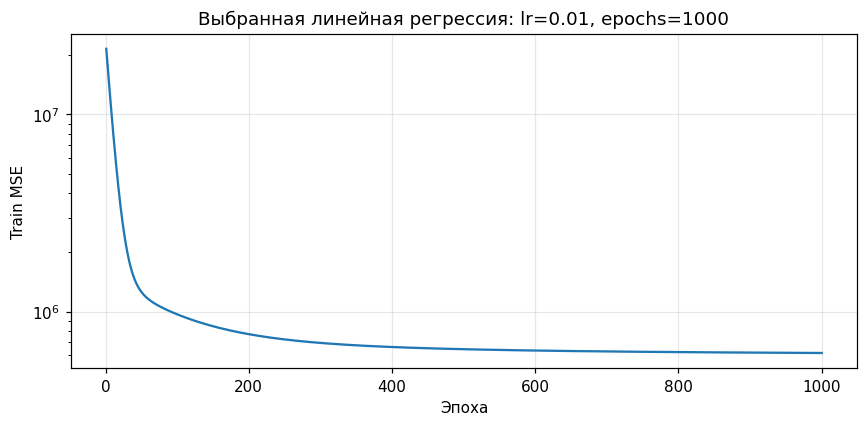

In [15]:
plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(1, len(best_linear_model.history_) + 1),
    best_linear_model.history_,
)

plt.title(
    "Выбранная линейная регрессия: "
    f"lr={best_linear_model.learning_rate}, "
    f"epochs={best_linear_model.epochs}"
)
plt.xlabel("Эпоха")
plt.ylabel("Train MSE")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Часть B. Логистическая регрессия
### Первичное исследование Spaceship Titanic

Один объект — один пассажир.
Целевая переменная `Transported` принимает значения False и True.

Используется размеченный файл `train.csv`, который будет
самостоятельно разделён на train, validation и test.
Конкурсный файл `test.csv` в эксперименте не используется.

In [16]:
spaceship_df = pd.read_csv(str(DATA_DIR / "train.csv"))

print("Размер датасета:", spaceship_df.shape)
display(spaceship_df.head())
spaceship_df.info()

spaceship_summary = pd.DataFrame({
    "dtype": spaceship_df.dtypes.astype(str),
    "missing": spaceship_df.isna().sum(),
    "missing_percent": spaceship_df.isna().mean() * 100,
    "unique": spaceship_df.nunique(),
})

display(spaceship_summary.round(2))

print(
    "Полностью совпадающих строк:",
    spaceship_df.duplicated().sum(),
)
print(
    "Повторяющихся PassengerId:",
    spaceship_df["PassengerId"].duplicated().sum(),
)

class_counts = spaceship_df["Transported"].value_counts().sort_index()

display(pd.DataFrame({
    "count": class_counts,
    "percent": class_counts / len(spaceship_df) * 100,
}).round(2))

display(spaceship_df.describe().T)

Размер датасета: (8693, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB
Полностью совпадающих строк: 0
Повторяющихся PassengerId: 0


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


,dtype,missing,missing_percent,unique
PassengerId,object,0,0.00,8693
HomePlanet,object,201,2.31,3
CryoSleep,object,217,2.50,2
Cabin,object,199,2.29,6560
Destination,object,182,2.09,3
Age,float64,179,2.06,80
VIP,object,203,2.34,2
RoomService,float64,181,2.08,1273
FoodCourt,float64,183,2.11,1507
ShoppingMall,float64,208,2.39,1115


,count,percent
Transported,,
False,4315,49.64
True,4378,50.36


,count,mean,std,min,25%,50%,75%,max
Age,8514.0,28.827930,14.489021,0.0,19.0,27.0,38.0,79.0
RoomService,8512.0,224.687617,666.717663,0.0,0.0,0.0,47.0,14327.0
FoodCourt,8510.0,458.077203,1611.489240,0.0,0.0,0.0,76.0,29813.0
ShoppingMall,8485.0,173.729169,604.696458,0.0,0.0,0.0,27.0,23492.0
Spa,8510.0,311.138778,1136.705535,0.0,0.0,0.0,59.0,22408.0
VRDeck,8505.0,304.854791,1145.717189,0.0,0.0,0.0,46.0,24133.0


### Разбиение данных

Целевая переменная `Transported` преобразована в числа:
False = 0, True = 1.

Используется собственное стратифицированное разбиение:
примерно 60% train, 20% validation и 20% test.
Доли классов сохраняются приблизительно одинаковыми
во всех трёх выборках.

`PassengerId` и `Name` исключены из входных признаков.
Исходный `Cabin` будет разделён на палубу, номер и сторону.

Заполнение пропусков, определение категорий и расчёт параметров
масштабирования выполняются только по train.
Конкурсный файл `test.csv` не используется.

Разбиение выполняется по пассажирам и не гарантирует,
что пассажиры одной группы окажутся в одной выборке.
Поэтому эксперимент не является отдельной проверкой
качества на полностью новых группах пассажиров.

In [17]:
from split import stratified_train_test_split_indices

spaceship_X_raw = spaceship_df.drop(
    columns=["Transported", "PassengerId", "Name"]
).copy()

spaceship_y_raw = spaceship_df["Transported"].astype(np.int64)

# Отделяем итоговый test.
spaceship_dev_indices, spaceship_test_indices = (
    stratified_train_test_split_indices(
        y=spaceship_y_raw.to_numpy(),
        test_size=0.2,
        random_state=SEED,
    )
)

# Четверть оставшихся данных выделяем под validation.
spaceship_train_positions, spaceship_val_positions = (
    stratified_train_test_split_indices(
        y=spaceship_y_raw.iloc[spaceship_dev_indices].to_numpy(),
        test_size=0.25,
        random_state=SEED + 1,
    )
)

spaceship_train_indices = (
    spaceship_dev_indices[spaceship_train_positions]
)
spaceship_val_indices = (
    spaceship_dev_indices[spaceship_val_positions]
)

spaceship_X_train_raw = spaceship_X_raw.iloc[
    spaceship_train_indices
].copy()

spaceship_X_val_raw = spaceship_X_raw.iloc[
    spaceship_val_indices
].copy()

spaceship_X_test_raw = spaceship_X_raw.iloc[
    spaceship_test_indices
].copy()

spaceship_y_train = spaceship_y_raw.iloc[
    spaceship_train_indices
].copy()

spaceship_y_val = spaceship_y_raw.iloc[
    spaceship_val_indices
].copy()

spaceship_y_test = spaceship_y_raw.iloc[
    spaceship_test_indices
].copy()

spaceship_all_indices = np.concatenate([
    spaceship_train_indices,
    spaceship_val_indices,
    spaceship_test_indices,
])

assert np.array_equal(
    np.sort(spaceship_all_indices),
    np.arange(len(spaceship_df)),
)

split_summary = pd.DataFrame(
    {
        "objects": [
            len(spaceship_y_train),
            len(spaceship_y_val),
            len(spaceship_y_test),
        ],
        "class_0": [
            int((part == 0).sum())
            for part in (
                spaceship_y_train,
                spaceship_y_val,
                spaceship_y_test,
            )
        ],
        "class_1": [
            int((part == 1).sum())
            for part in (
                spaceship_y_train,
                spaceship_y_val,
                spaceship_y_test,
            )
        ],
        "class_1_percent": [
            part.mean() * 100
            for part in (
                spaceship_y_train,
                spaceship_y_val,
                spaceship_y_test,
            )
        ],
    },
    index=["Train", "Validation", "Test"],
)

display(split_summary.round(2))

print("Количество исходных признаков:", spaceship_X_train_raw.shape[1])
print("Проверка пройдена: все строки распределены без пересечений.")

Количество исходных признаков: 11
Проверка пройдена: все строки распределены без пересечений.


,objects,class_0,class_1,class_1_percent
Train,5215,2589,2626,50.35
Validation,1739,863,876,50.37
Test,1739,863,876,50.37


### Предобработка Spaceship Titanic

Признак `Cabin` разделён на палубу, номер и сторону каюты.

Пропуски в числовых признаках заполняются медианами train.
К пяти признакам расходов применяется преобразование log1p,
уменьшающее влияние больших значений.
После этого числовые признаки стандартизируются.

Категориальные признаки, включая `CryoSleep` и `VIP`,
преобразуются в строки. Пропуски обозначаются категорией Unknown.
Используется собственное one-hot кодирование.
Категории, не встречавшиеся при обучении, преобразуются в Unknown.

Все параметры предобработки определяются только по train.
К validation и test применяются сохранённые параметры.
Строки с пропусками не удаляются.

In [18]:
from preprocessing import SpaceshipPreprocessor

spaceship_preprocessor = SpaceshipPreprocessor()

spaceship_X_train = spaceship_preprocessor.fit_transform(
    spaceship_X_train_raw
)
spaceship_X_val = spaceship_preprocessor.transform(
    spaceship_X_val_raw
)
spaceship_X_test = spaceship_preprocessor.transform(
    spaceship_X_test_raw
)

print("Train:", spaceship_X_train.shape)
print("Validation:", spaceship_X_val.shape)
print("Test:", spaceship_X_test.shape)

print("\nПризнаки после преобразования:")
print(spaceship_preprocessor.feature_names_)

assert (
    spaceship_X_train.shape[1]
    == spaceship_X_val.shape[1]
    == spaceship_X_test.shape[1]
    == len(spaceship_preprocessor.feature_names_)
)

assert spaceship_X_train.shape[0] == len(spaceship_y_train)
assert spaceship_X_val.shape[0] == len(spaceship_y_val)
assert spaceship_X_test.shape[0] == len(spaceship_y_test)

for values in (
    spaceship_X_train,
    spaceship_X_val,
    spaceship_X_test,
):
    assert np.isfinite(values).all()

print("\nПроверка пройдена: размерности согласованы, NaN и inf нет.")

Train: (5215, 33)
Validation: (1739, 33)
Test: (1739, 33)

Признаки после преобразования:
['Age', 'CabinNumber', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'HomePlanet=Earth', 'HomePlanet=Europa', 'HomePlanet=Mars', 'HomePlanet=Unknown', 'Destination=55 Cancri e', 'Destination=PSO J318.5-22', 'Destination=TRAPPIST-1e', 'Destination=Unknown', 'CryoSleep=False', 'CryoSleep=True', 'CryoSleep=Unknown', 'VIP=False', 'VIP=True', 'VIP=Unknown', 'CabinDeck=A', 'CabinDeck=B', 'CabinDeck=C', 'CabinDeck=D', 'CabinDeck=E', 'CabinDeck=F', 'CabinDeck=G', 'CabinDeck=T', 'CabinDeck=Unknown', 'CabinSide=P', 'CabinSide=S', 'CabinSide=Unknown']

Проверка пройдена: размерности согласованы, NaN и inf нет.


In [19]:
n_spaceship_numeric = len(
    spaceship_preprocessor.numeric_columns
)

spaceship_scaling_check = pd.DataFrame(
    {
        "train_mean": spaceship_X_train[
            :, :n_spaceship_numeric
        ].mean(axis=0),
        "train_std": spaceship_X_train[
            :, :n_spaceship_numeric
        ].std(axis=0),
        "val_mean": spaceship_X_val[
            :, :n_spaceship_numeric
        ].mean(axis=0),
        "val_std": spaceship_X_val[
            :, :n_spaceship_numeric
        ].std(axis=0),
    },
    index=spaceship_preprocessor.numeric_columns,
)

display(spaceship_scaling_check.round(6))

print("Медианы train до log1p и стандартизации:")
display(spaceship_preprocessor.medians_)

Медианы train до log1p и стандартизации:


,train_mean,train_std,val_mean,val_std
Age,-0.0,1.0,-0.015752,1.013689
CabinNumber,0.0,1.0,-0.019524,0.987761
RoomService,0.0,1.0,0.006668,0.998201
FoodCourt,-0.0,1.0,0.014835,0.995077
ShoppingMall,-0.0,1.0,0.029686,1.019949
Spa,-0.0,1.0,-0.014201,0.995281
VRDeck,0.0,1.0,-0.007504,0.998527


Age              27.0
CabinNumber     419.0
RoomService       0.0
FoodCourt         0.0
ShoppingMall      0.0
Spa               0.0
VRDeck            0.0
dtype: float64

### Обучение логистической регрессии

Реализована собственная логистическая регрессия:

z = Xw + b,
p = sigmoid(z).

Функция потерь — BCE / LogLoss.
Для численной устойчивости BCE вычисляется через logits
в эквивалентной форме:

mean(max(z, 0) - y*z + log(1 + exp(-abs(z)))).

Обучение выполняется полным градиентным спуском.
Градиенты и обновление весов реализованы вручную.
Начальные веса и свободный член равны нулю.

Метод predict_proba возвращает вероятность класса 1.
Метод predict применяет порог 0.5.

Начальные настройки: learning_rate = 0.05, epochs = 3000.
Test при обучении и выборе настроек не используется.

In [20]:
from models.logistic_regression import LogisticRegression

logistic_model = LogisticRegression(
    learning_rate=0.05,
    epochs=3000,
    threshold=0.5,
)

logistic_model.fit(
    spaceship_X_train,
    spaceship_y_train.to_numpy(),
)

print("Количество весов:", len(logistic_model.weights_))
print("Свободный член:", logistic_model.bias_.item())
print("Количество записей loss:", len(logistic_model.history_))

print(
    "BCE после первой эпохи:",
    f"{logistic_model.history_[0]:.6f}",
)
print(
    "BCE после последней эпохи:",
    f"{logistic_model.history_[-1]:.6f}",
)

Количество весов: 33
Свободный член: 0.13574440311897595
Количество записей loss: 3000
BCE после первой эпохи: 0.686369
BCE после последней эпохи: 0.476891


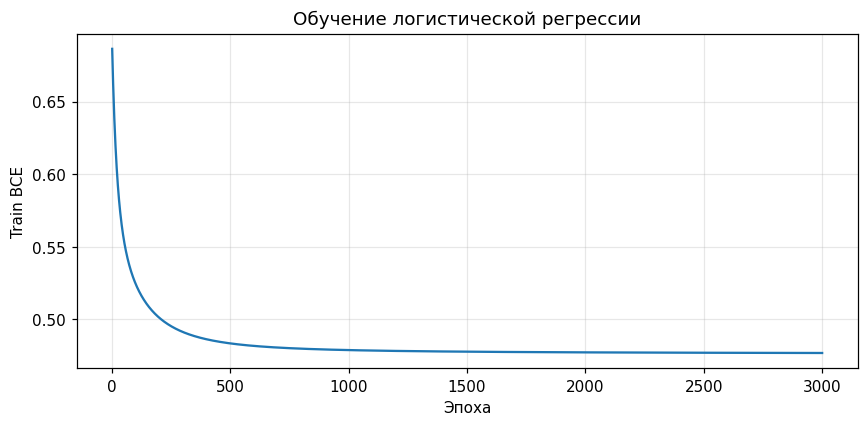

In [21]:
plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(1, len(logistic_model.history_) + 1),
    logistic_model.history_,
)

plt.title("Обучение логистической регрессии")
plt.xlabel("Эпоха")
plt.ylabel("Train BCE")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
spaceship_val_probabilities = logistic_model.predict_proba(
    spaceship_X_val
)
spaceship_val_predictions = logistic_model.predict(
    spaceship_X_val
)

assert spaceship_val_probabilities.shape == spaceship_y_val.shape
assert np.isfinite(spaceship_val_probabilities).all()
assert (
    (spaceship_val_probabilities >= 0)
    & (spaceship_val_probabilities <= 1)
).all()

spaceship_validation_preview = pd.DataFrame({
    "actual": spaceship_y_val.to_numpy(),
    "probability_1": spaceship_val_probabilities,
    "predicted": spaceship_val_predictions,
})

display(spaceship_validation_preview.head(10).round(4))

spaceship_val_accuracy = np.mean(
    spaceship_val_predictions == spaceship_y_val.to_numpy()
)

# Защита логарифмов при оценке по вероятностям.
safe_probabilities = np.clip(
    spaceship_val_probabilities,
    1e-15,
    1 - 1e-15,
)

actual_validation = spaceship_y_val.to_numpy()

spaceship_val_logloss = -np.mean(
    actual_validation * np.log(safe_probabilities)
    + (1 - actual_validation) * np.log1p(-safe_probabilities)
)

print(f"Validation Accuracy: {spaceship_val_accuracy:.4f}")
print(f"Validation LogLoss: {spaceship_val_logloss:.6f}")

Validation Accuracy: 0.7671
Validation LogLoss: 0.480083


,actual,probability_1,predicted
0,0,0.1063,0
1,1,0.8018,1
2,0,0.6609,1
3,1,0.8248,1
4,0,0.1019,0
5,1,0.0656,0
6,1,0.7591,1
7,1,0.7620,1
8,1,0.8295,1
9,1,0.9039,1


### Выбор настроек логистической регрессии

Сравниваются четыре комбинации:
- learning_rate = 0.01, epochs = 1000;
- learning_rate = 0.05, epochs = 1000;
- learning_rate = 0.05, epochs = 3000;
- learning_rate = 0.1, epochs = 3000.

Критерий выбора — минимальный LogLoss на validation,
поскольку модель обучается предсказывать вероятности.
При равенстве выбирается первый рассмотренный вариант.

Порог классификации фиксирован и равен 0.5.
Test не используется для выбора настроек.

In [23]:
from evaluation import classification_metrics

logistic_configurations = [
    (0.01, 1000),
    (0.05, 1000),
    (0.05, 3000),
    (0.1, 3000),
]

logistic_experiments = []
logistic_candidates = []

for learning_rate, epochs in logistic_configurations:
    if (
        learning_rate == logistic_model.learning_rate
        and epochs == logistic_model.epochs
    ):
        candidate = logistic_model
    else:
        candidate = LogisticRegression(
            learning_rate=learning_rate,
            epochs=epochs,
            threshold=0.5,
        )
        candidate.fit(
            spaceship_X_train,
            spaceship_y_train.to_numpy(),
        )

    val_metrics = classification_metrics(
        spaceship_y_val,
        candidate.predict_proba(spaceship_X_val),
        threshold=candidate.threshold,
    )

    logistic_experiments.append({
        "learning_rate": learning_rate,
        "epochs": epochs,
        "train_BCE": candidate.history_[-1],
        "val_LogLoss": val_metrics["LogLoss"],
        "val_Accuracy": val_metrics["Accuracy"],
        "val_F1": val_metrics["F1"],
    })

    logistic_candidates.append(candidate)

logistic_search_results = pd.DataFrame(logistic_experiments)

display(
    logistic_search_results.sort_values(
        "val_LogLoss",
        kind="stable",
    ).round(6)
)

best_logistic_index = int(
    logistic_search_results["val_LogLoss"].idxmin()
)
best_logistic_model = logistic_candidates[best_logistic_index]

print("Выбранные настройки:")
print("learning_rate:", best_logistic_model.learning_rate)
print("epochs:", best_logistic_model.epochs)
print("threshold:", best_logistic_model.threshold)

Выбранные настройки:
learning_rate: 0.1
epochs: 3000
threshold: 0.5


,learning_rate,epochs,train_BCE,val_LogLoss,val_Accuracy,val_F1
3,0.10,3000,0.476508,0.479952,0.768833,0.776418
2,0.05,3000,0.476891,0.480083,0.767108,0.775125
1,0.05,1000,0.478882,0.481633,0.767108,0.776119
0,0.01,1000,0.501210,0.502987,0.767683,0.769406


### Итоговая оценка и majority baseline

Majority baseline всем объектам предсказывает наиболее частый
класс обучающей выборки.

Для расчёта LogLoss baseline использует постоянную вероятность,
равную доле класса 1 на train. При пороге 0.5 это даёт
предсказание наиболее частого класса.

Выбранная по validation модель и baseline оцениваются
на одинаковой тестовой выборке.
После выбора настроек модель не переобучается на train + validation.

Рассчитываются Accuracy, Precision, Recall, F1 и LogLoss.
Положительный класс — Transported=True.

In [24]:
spaceship_baseline_probability = float(spaceship_y_train.mean())
spaceship_majority_class = int(
    spaceship_baseline_probability >= 0.5
)

spaceship_baseline_probabilities = np.full(
    len(spaceship_y_test),
    spaceship_baseline_probability,
    dtype=np.float64,
)

spaceship_test_probabilities = best_logistic_model.predict_proba(
    spaceship_X_test
)

logistic_test_metrics = classification_metrics(
    spaceship_y_test,
    spaceship_test_probabilities,
    threshold=best_logistic_model.threshold,
)

majority_test_metrics = classification_metrics(
    spaceship_y_test,
    spaceship_baseline_probabilities,
    threshold=0.5,
)

classification_metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "LogLoss",
]

classification_test_results = pd.DataFrame(
    [majority_test_metrics, logistic_test_metrics],
    index=["Majority baseline", "Logistic Regression"],
)

print("Класс majority baseline:", spaceship_majority_class)
print(
    "Вероятность класса 1 у baseline:",
    f"{spaceship_baseline_probability:.6f}",
)

display(
    classification_test_results[
        classification_metric_names
    ].round(6)
)

display(
    classification_test_results[
        ["TP", "FP", "FN", "TN"]
    ]
)

Класс majority baseline: 1
Вероятность класса 1 у baseline: 0.503547


,Accuracy,Precision,Recall,F1,LogLoss
Majority baseline,0.503738,0.503738,1.000000,0.669981,0.693119
Logistic Regression,0.776883,0.768132,0.797945,0.782755,0.478761


,TP,FP,FN,TN
Majority baseline,876,863,0,0
Logistic Regression,699,211,177,652


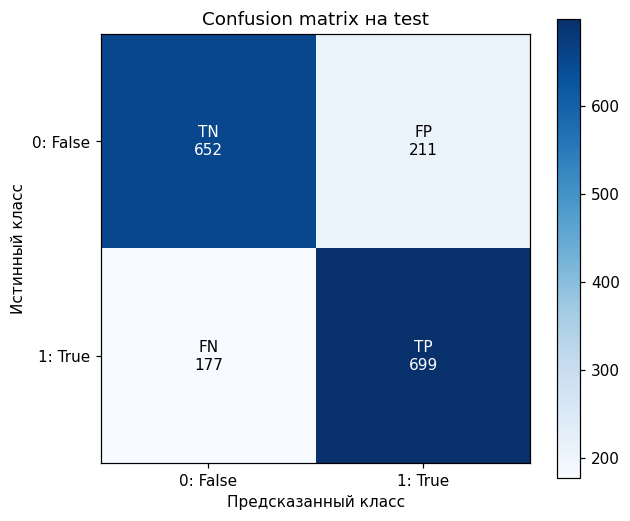

In [25]:
confusion = np.array([
    [logistic_test_metrics["TN"], logistic_test_metrics["FP"]],
    [logistic_test_metrics["FN"], logistic_test_metrics["TP"]],
], dtype=np.int64)

assert confusion.sum() == len(spaceship_y_test)

fig, ax = plt.subplots(figsize=(6, 5))

heatmap = ax.imshow(confusion, cmap="Blues")

ax.set_xticks([0, 1], labels=["0: False", "1: True"])
ax.set_yticks([0, 1], labels=["0: False", "1: True"])
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title("Confusion matrix на test")

cell_names = [
    ["TN", "FP"],
    ["FN", "TP"],
]

for row in range(2):
    for column in range(2):
        value = confusion[row, column]

        ax.text(
            column,
            row,
            f"{cell_names[row][column]}\n{value}",
            ha="center",
            va="center",
            color=(
                "white"
                if value > confusion.max() / 2
                else "black"
            ),
        )

fig.colorbar(heatmap, ax=ax)
plt.tight_layout()
plt.show()

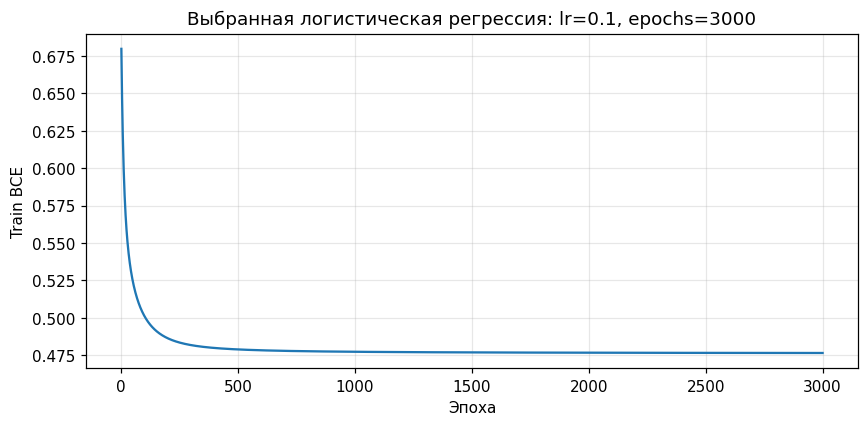

In [26]:
plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(1, len(best_logistic_model.history_) + 1),
    best_logistic_model.history_,
)

plt.title(
    "Выбранная логистическая регрессия: "
    f"lr={best_logistic_model.learning_rate}, "
    f"epochs={best_logistic_model.epochs}"
)
plt.xlabel("Эпоха")
plt.ylabel("Train BCE")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Вывод по логистической регрессии

Реализована собственная логистическая регрессия на PyTorch.
Предсказания вычисляются как sigmoid(Xw + b).
Обучение выполняется полным градиентным спуском с ручным
вычислением градиентов и обновлением параметров.
Функция потерь — численно устойчивая форма BCE.

Данные разделены стратифицированно на train, validation и test.
Пропуски числовых признаков заполнены медианами train.
К расходам применено преобразование log1p, затем числовые
признаки стандартизированы. Категории закодированы one-hot.
Признак Cabin разделён на палубу, номер и сторону.
Все параметры предобработки определялись только по train.

Из четырёх комбинаций по минимальному LogLoss на validation
выбраны learning_rate = 0.1 и 3000 эпох.
Порог классификации зафиксирован на уровне 0.5.

На test получены:
- Accuracy = 0.7769;
- Precision = 0.7681;
- Recall = 0.7979;
- F1 = 0.7828;
- LogLoss = 0.4788.

Модель правильно классифицировала 1351 из 1739 пассажиров.
Матрица ошибок: TN = 652, FP = 211, FN = 177, TP = 699.

Majority baseline предсказывает всем класс 1 и получает
Accuracy = 0.5037, F1 = 0.6700 и LogLoss = 0.6931.
Логистическая регрессия повышает Accuracy на 27.31 процентного
пункта и снижает LogLoss.

Recall baseline равен 1, поскольку он относит всех пассажиров
к положительному классу. Это сопровождается 863 ложными
положительными ответами и показывает необходимость оценивать
несколько метрик.

Значения loss на train, validation и test близки;
сильного переобучения в проведённом эксперименте не наблюдается.
Оценка относится к разбиению по пассажирам, а не по целым
группам пассажиров.

## Проверка собственных метрик
Метрики вычисляются повторно через разрешённый модуль `sklearn.metrics`.
Проверки `assert_allclose` учитывают погрешность вычислений с плавающей точкой.
При расхождении возникает AssertionError; сообщение об успехе выводится только после всех проверок.
Эта проверка относится к метрикам, а не ко всей корректности модели и предобработки.

In [27]:
from sklearn import metrics as sklearn_metrics

# Эталонные значения рассчитываются на тех же ответах и прогнозах.
regression_ours = np.array([
    model_test_metrics["MAE"],
    model_test_metrics["RMSE"],
    model_test_metrics["R2"],
])
regression_reference = np.array([
    sklearn_metrics.mean_absolute_error(y_test, test_predictions),
    np.sqrt(sklearn_metrics.mean_squared_error(y_test, test_predictions)),
    sklearn_metrics.r2_score(y_test, test_predictions),
])

final_class_predictions = best_logistic_model.predict(spaceship_X_test)
classification_ours = np.array([
    logistic_test_metrics[name]
    for name in classification_metric_names
])
classification_reference = np.array([
    sklearn_metrics.accuracy_score(spaceship_y_test, final_class_predictions),
    sklearn_metrics.precision_score(
        spaceship_y_test, final_class_predictions, zero_division=0,
    ),
    sklearn_metrics.recall_score(
        spaceship_y_test, final_class_predictions, zero_division=0,
    ),
    sklearn_metrics.f1_score(
        spaceship_y_test, final_class_predictions, zero_division=0,
    ),
    sklearn_metrics.log_loss(
        spaceship_y_test,
        np.clip(spaceship_test_probabilities, 1e-15, 1 - 1e-15),
        labels=[0, 1],
    ),
])

np.testing.assert_allclose(
    regression_ours, regression_reference, rtol=1e-10, atol=1e-12,
)
np.testing.assert_allclose(
    classification_ours, classification_reference, rtol=1e-10, atol=1e-12,
)
np.testing.assert_array_equal(
    confusion,
    sklearn_metrics.confusion_matrix(
        spaceship_y_test, final_class_predictions, labels=[0, 1],
    ),
)

metric_names = ["Regression MAE", "Regression RMSE", "Regression R2"] + [
    f"Classification {name}" for name in classification_metric_names
]
ours = np.concatenate([regression_ours, classification_ours])
reference = np.concatenate([regression_reference, classification_reference])
comparison = pd.DataFrame({
    "Собственная реализация": ours,
    "sklearn.metrics": reference,
    "Абсолютная разница": np.abs(ours - reference),
}, index=metric_names)

with pd.option_context("display.precision", 12):
    display(comparison)

print("Собственные метрики и confusion matrix совпадают со sklearn.")


Собственные метрики и confusion matrix совпадают со sklearn.


,Собственная реализация,sklearn.metrics,Абсолютная разница
Regression MAE,555.920489129878,555.920489129878,0.000000000000e+00
Regression RMSE,723.359478051747,723.359478051747,0.000000000000e+00
Regression R2,0.842424526419,0.842424526419,0.000000000000e+00
Classification Accuracy,0.776883266245,0.776883266245,0.000000000000e+00
Classification Precision,0.768131868132,0.768131868132,0.000000000000e+00
Classification Recall,0.797945205479,0.797945205479,0.000000000000e+00
Classification F1,0.782754759239,0.782754759239,0.000000000000e+00
Classification LogLoss,0.478761085205,0.478761085205,5.551115123126e-17
